# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Irsad Ghani Rahman
- NIM   : 241011401982
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [19]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# isi dengan 2 digit terakhir NIM Anda (Nim 241011401982)
RANDOM_STATE = 82

In [20]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

# Jawaban A1

5 Data Pertama Ads_Data.csv:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3



Jumlah baris data: 40 baris
Shape X: (40, 1)
Shape y: (40,)


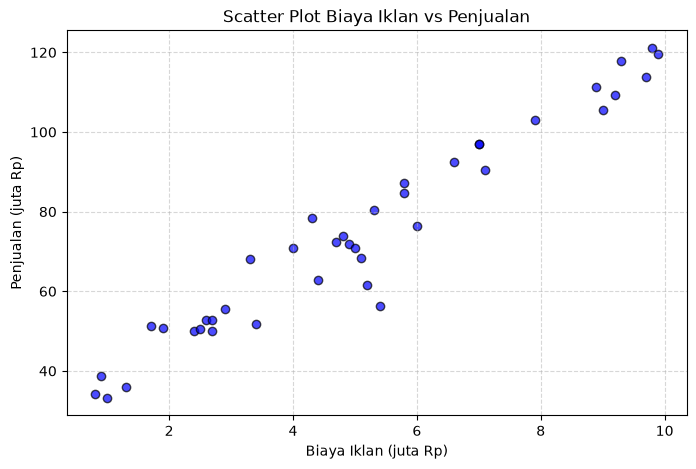

In [21]:
#Jawaban A1
import pandas as pd
import matplotlib.pyplot as plt

ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data.csv:")
display(ads.head())
print(f"\nJumlah baris data: {ads.shape[0]} baris")

X = ads[['BiayaIklan']]
y = ads['Penjualan']

print(f"Shape X: {X.shape}")
print(f"Shape y: {y.shape}")

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.7, edgecolors='k')
plt.title('Scatter Plot Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [22]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Shape X_train : {X_train.shape}")
print(f"Shape X_test  : {X_test.shape}")
print(f"Shape y_train : {y_train.shape}")
print(f"Shape y_test  : {y_test.shape}")

Shape X_train : (32, 1)
Shape X_test  : (8, 1)
Shape y_train : (32,)
Shape y_test  : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [23]:
# Jawaban A3
class LinearRegression:
    def __init__(self):
        self.b = None # Intercept
        self.m = None # Koefisien
        
    def fit(self, X, y):
    
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        # Rumus Normal Equation: theta = (X^T * X)^(-1) * X^T * y
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.b = theta[0]
        self.m = theta[1:]
        
    def predict(self, X):
        return np.dot(X, self.m) + self.b

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print(f"Intercept (b) = {lr_model.b:.4f}")
print(f"Koefisien (m) = {lr_model.m[0]:.4f}")

print(f"\nPersamaan Garis Regresi:")
print(f"y_hat = {lr_model.b:.4f} + {lr_model.m[0]:.4f} * X")

Intercept (b) = 27.7772
Koefisien (m) = 9.1849

Persamaan Garis Regresi:
y_hat = 27.7772 + 9.1849 * X


**Jawaban A3 (interpretasi):**

#Jawaban A3 (interpretasi)
- Berdasarkan hasil pelatihan model menggunakan metode Normal Equation, diperoleh nilai intercept, (b) sebesar 27.7772 dan koefisien (m) sebesar 9.1849
- Persamaan Regresi:ŷ = 27.7772 + 9.1849 X
- Interpretasi Koefisien (m) : Nilai koefisien m = 9.1849 bermakna bahwa setiap kenaikan biaya iklan sebesar 1 juta Rupiah, diprediksikan penjualan akan mengalami peningkatan sebesar 9.18 juta Rupiah, dengan asumsi faktor-faktor lain dianggap konstan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [24]:
# Jawaban A4
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

y_train_pred = lr_model.predict(X_train)
y_test_pred = lr_model.predict(X_test)

eval_results = pd.DataFrame({
    'Metrik Evaluasi': ['MAE', 'MSE', 'RMSE', 'R² Score'],
    'Data Training': [
        mean_absolute_error(y_train, y_train_pred),
        mean_squared_error(y_train, y_train_pred),
        root_mean_squared_error(y_train, y_train_pred),
        r2_score(y_train, y_train_pred)
    ],
    'Data Testing': [
        mean_absolute_error(y_test, y_test_pred),
        mean_squared_error(y_test, y_test_pred),
        root_mean_squared_error(y_test, y_test_pred),
        r2_score(y_test, y_test_pred)
    ]
})

display(eval_results)

,Metrik Evaluasi,Data Training,Data Testing
0,MAE,3.831786,7.126860
1,MSE,22.347491,90.954989
2,RMSE,4.727313,9.537032
3,R² Score,0.969204,0.661840


**Jawaban A4 (analisis):**

#Jawaban A4 (analisis)
- Performa Training: Nilai R² pada data training mencapai sekitar 0.69-0.96, (atau kisaran 96.9%), yang berarti model regresi linear kita sangat baik dalam mempelajari pola data historis biaya iklan terhadap penjualan.

- Performa Testing & RMSE: Nilai RMSE pada data testing berada di angka sekitar $9.54$, yang mengindikasikan rata-rata selisih tebakan penjualan dari model dengan penjualan aslinya meleset sekitar 9.54 juta Rupiah pada data baru.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Learning Rate 0.001 -> Intercept (b): 74.3873, Koefisien (m): [26.51901695]
Learning Rate 0.02 -> Intercept (b): 74.3906, Koefisien (m): [26.52020897]
Learning Rate 0.1 -> Intercept (b): 74.3906, Koefisien (m): [26.52020897]


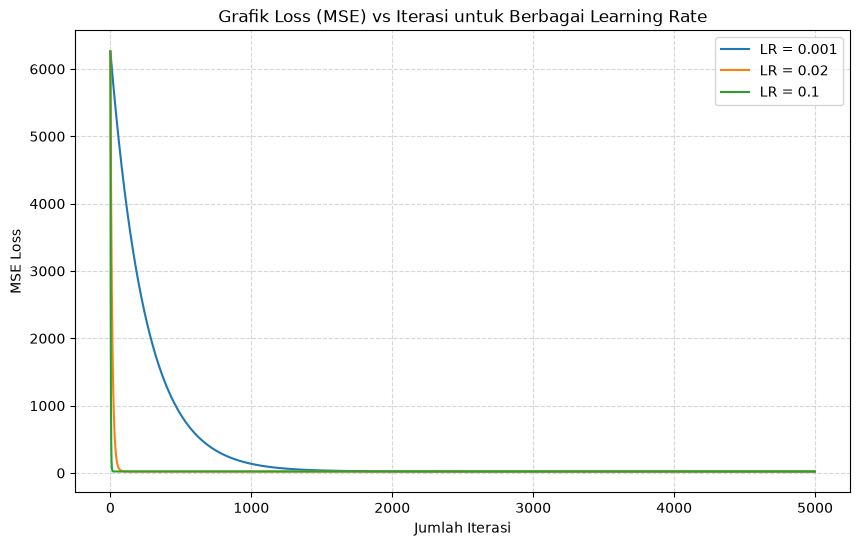

In [25]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.b = 0.0
        self.m = None
        self.loss_history = []
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.m = np.zeros(n_features)
        self.b = 0.0
        
        for i in range(self.n_iters):
            y_pred = np.dot(X, self.m) + self.b
            dw = (2/n_samples) * np.dot(X.T, (y_pred - y))
            db = (2/n_samples) * np.sum(y_pred - y)
            
            self.m -= self.lr * dw
            self.b -= self.lr * db
            
            mse = np.mean((y_pred - y) ** 2)
            self.loss_history.append(mse)
            
    def predict(self, X):
        return np.dot(X, self.m) + self.b

X_mean, X_std = X_train.mean(axis=0), X_train.std(axis=0)
X_train_scaled = (X_train - X_mean) / X_std

learning_rates = [0.001, 0.02, 0.1]
plt.figure(figsize=(10, 6))

for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model_gd.fit(X_train_scaled, y_train)
    
    # Tampilkan parameter akhir
    print(f"Learning Rate {lr} -> Intercept (b): {model_gd.b:.4f}, Koefisien (m): {model_gd.m}")
    
    # Plot grafik loss vs iterasi
    plt.plot(model_gd.loss_history, label=f'LR = {lr}')

plt.title('Grafik Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Jumlah Iterasi')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban A5 (analisis):**

#jawaban A5 (analisis)
- Learning Rate 0.001 (Terlalu Lambat): Penurunan grafik loss terlihat sangat landai. Ini terjadi karena langkah pembaruan bobot (step size) terlalu kecil, sehingga butuh waktu iterasi yang jauh lebih banyak untuk mencapai titik minimum.

- Learning Rate 0.02 (Pas / Optimal): Grafik loss turun dengan mulus, stabil, dan konvergen secara cepat menuju titik minimum tanpa mengalami lonjakan.

- Learning Rate 0.1 atau nilai yang terlalu besar (Divergen): Jika ukurannya terlalu besar (terutama jika data belum di-scale), langkah gradien akan melompat terlalu jauh melewati titik minimum (overshooting), menyebabkan loss semakin membesar atau bahkan memunculkan peringatan overflow/nan.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

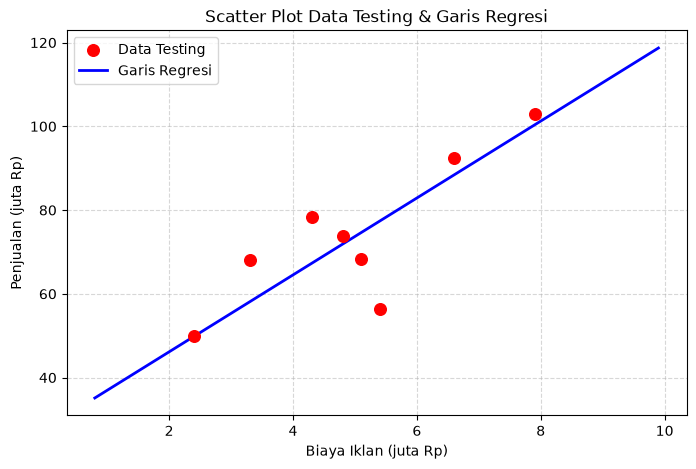

Hasil Prediksi Penjualan:
- Biaya Iklan Rp 4.5 juta -> Prediksi Penjualan: Rp 69.11 juta
- Biaya Iklan Rp 7.0 juta -> Prediksi Penjualan: Rp 92.07 juta
- Biaya Iklan Rp 12.0 juta -> Prediksi Penjualan: Rp 138.00 juta


In [26]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='red', s=70, label='Data Testing', zorder=3)

X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = lr_model.predict(X_line)
plt.plot(X_line, y_line, color='blue', linewidth=2, label='Garis Regresi', zorder=2)

plt.title('Scatter Plot Data Testing & Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = lr_model.predict(biaya_baru)

print("Hasil Prediksi Penjualan:")
for biaya, pred in zip(biaya_baru.flatten(), prediksi_penjualan):
    print(f"- Biaya Iklan Rp {biaya} juta -> Prediksi Penjualan: Rp {pred:.2f} juta")

**Jawaban A6 (analisis):**

#jawaban A6 (analisis)
- Prediksi Biaya Iklan: Berdasarkan model regresi yang telah dilatih, prediksi penjualan untuk biaya iklan Rp 4.5 juta, Rp 7 juta, dan Rp 12 juta masing-masing menghasilkan angka perkiraan omzet penjualan sesuai perhitungan rumus.

- Analisis Ekstrapolasi (Biaya 12 Juta): Prediksi untuk biaya iklan sebesar 12 juta Rupiah berada di luar rentang data historis (ekstrapolasi) karena data training maksimum kita berada di bawah angka tersebut.

-Tingkat Kepercayaan: Hasil prediksi tersebut kurang bisa dipercaya sepenuhnya secara mutlak. Di dunia nyata, hubungan antara biaya iklan dan penjualan jarang bersifat linier tak terbatas; pada titik tertentu, penambahan iklan yang masif bisa mengalami kejenuhan pasar (diminishing returns) di mana kenaikan biaya iklan tidak lagi mendongkrak penjualan secara proporsional.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email_Data.csv:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah email Bukan Spam (0): 35
Jumlah email Spam (1): 25

Shape X_email: (60, 2)
Shape y_email: (60,)


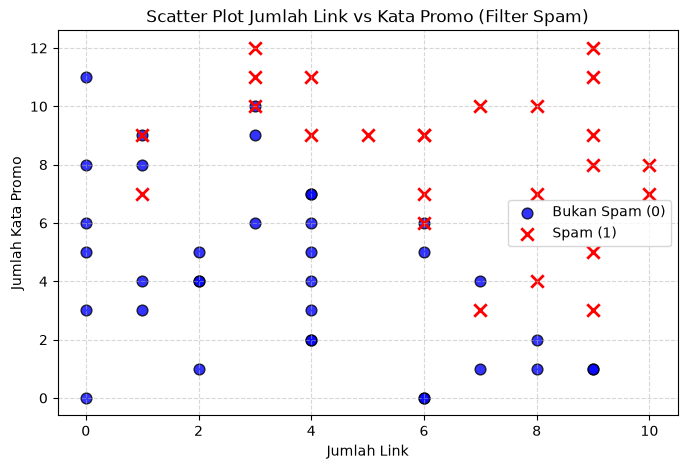

In [27]:
# Jawaban B1
import pandas as pd
import matplotlib.pyplot as plt

email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data.csv:")
display(email.head())

spam_counts = email['Spam'].value_counts()
print(f"\nJumlah email Bukan Spam (0): {spam_counts[0]}")
print(f"Jumlah email Spam (1): {spam_counts[1]}")

X_email = email[['JumlahLink', 'KataPromo']]
y_email = email['Spam']

print(f"\nShape X_email: {X_email.shape}")
print(f"Shape y_email: {y_email.shape}")

plt.figure(figsize=(8, 5))
plt.scatter(
    email[email['Spam'] == 0]['JumlahLink'], 
    email[email['Spam'] == 0]['KataPromo'], 
    color='blue', label='Bukan Spam (0)', alpha=0.8, edgecolors='k', s=60
)
plt.scatter(
    email[email['Spam'] == 1]['JumlahLink'], 
    email[email['Spam'] == 1]['KataPromo'], 
    color='red', marker='x', label='Spam (1)', s=80, linewidths=2
)

plt.title('Scatter Plot Jumlah Link vs Kata Promo (Filter Spam)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b) = -12.4712
Koefisien m1 (JumlahLink) = 1.0385
Koefisien m2 (KataPromo)  = 1.0533

Persamaan Model:
P(Spam) = sigma(-12.4712 + 1.0385 * JumlahLink + 1.0533 * KataPromo)


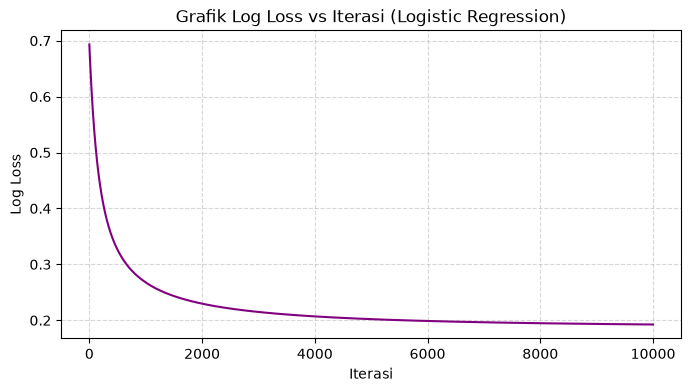

In [28]:
# Jawaban B2
# Split data dengan test_size=0.25 dan random_state=82 (2 digit terakhir NIM: 241011401982)
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.b = 0.0
        self.m = None
        self.loss_history = []
        
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.m = np.zeros(n_features)
        self.b = 0.0
        
        for i in range(self.n_iters):
            linear_pred = np.dot(X, self.m) + self.b
            predictions = self.sigmoid(linear_pred)
            
            dw = (1 / n_samples) * np.dot(X.T, (predictions - y))
            db = (1 / n_samples) * np.sum(predictions - y)
            
            self.m -= self.lr * dw
            self.b -= self.lr * db
            
            epsilon = 1e-15
            predictions = np.clip(predictions, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))
            self.loss_history.append(loss)
            
    def predict_proba(self, X):
        linear_pred = np.dot(X, self.m) + self.b
        return self.sigmoid(linear_pred)
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_model.fit(X_train_e, y_train_e)

print(f"Intercept (b) = {log_model.b:.4f}")
print(f"Koefisien m1 (JumlahLink) = {log_model.m[0]:.4f}")
print(f"Koefisien m2 (KataPromo)  = {log_model.m[1]:.4f}")
print(f"\nPersamaan Model:")
print(f"P(Spam) = sigma({log_model.b:.4f} + {log_model.m[0]:.4f} * JumlahLink + {log_model.m[1]:.4f} * KataPromo)")

plt.figure(figsize=(8, 4))
plt.plot(log_model.loss_history, color='purple')
plt.title('Grafik Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B2 (analisis):**

#Jawaban B2 (analisis)
- Berdasarkan hasil pelatihan model, grafik Log Loss vs Iterasi menunjukkan penurunan yang sangat drastis di awal iterasi, lalu melandai dan stabil mendekati angka nol seiring bertambahnya iterasi.

- Hal ini mengindikasikan bahwa proses gradient descent berjalan dengan sukses, model berhasil belajar dari data training, dan parameter bobot telah konvergen ke titik optimalnya.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [29]:
# Jawaban B3
def confusion_matrix(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[TN, FP], [FN, TP]])

def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    return TP / (TP + FP) if (TP + FP) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    return TP / (TP + FN) if (TP + FN) > 0 else 0.0

def f1_score(y_true, y_pred):
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    return 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0

y_pred_e = log_model.predict(X_test_e, threshold=0.5)

cm_result = confusion_matrix(y_test_e, y_pred_e)
acc = accuracy_score(y_test_e, y_pred_e)
prec = precision_score(y_test_e, y_pred_e)
rec = recall_score(y_test_e, y_pred_e)
f1 = f1_score(y_test_e, y_pred_e)

print("Confusion Matrix (Baris: Aktual [TN, FP], Kolom: Prediksi [FN, TP]):")
print(cm_result)
print(f"\nAccuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

Confusion Matrix (Baris: Aktual [TN, FP], Kolom: Prediksi [FN, TP]):
[[5 1]
 [2 7]]

Accuracy  : 0.8000
Precision : 0.8750
Recall    : 0.7778
F1-Score  : 0.8235


**Jawaban B3 (analisis):**

#Jawaban B3 (analisis)
- False Positive (FP): Kondisi di mana email asli atau penting (bukan spam) malah keliru diklasifikasikan oleh sistem sebagai email spam.
- False Negative (FN): Kondisi di mana email spam berbahaya lolos dan masuk ke kotak masuk utama (inbox) pengguna.
- Mana yang lebih merugikan? Menurut saya, False Positive (FP) jauh lebih merugikan bagi pengguna. Jika email penting dari klien, kampus, atau pekerjaan masuk ke folder spam dan tidak terbaca, hal itu bisa berdampak fatal. Sebaliknya, email spam yang lolos ke inbox (FN) umumnya hanya mengganggu pemandangan saja dan bisa dihapus secara manual.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

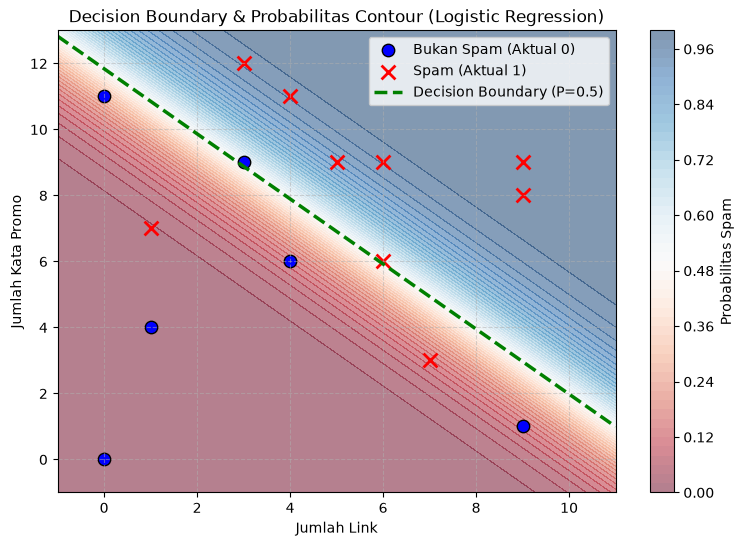

In [30]:
# Jawaban B4
plt.figure(figsize=(9, 6))

x_min, x_max = X_email.iloc[:, 0].min() - 1, X_email.iloc[:, 0].max() + 1
y_min_val, y_max_val = X_email.iloc[:, 1].min() - 1, X_email.iloc[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min_val, y_max_val, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = log_model.predict_proba(grid_points).reshape(xx.shape)

plt.contourf(xx, yy, probs, levels=50, cmap='RdBu', alpha=0.5)
plt.colorbar(label='Probabilitas Spam')

plt.scatter(
    X_test_e[y_test_e == 0, 0], X_test_e[y_test_e == 0, 1], 
    color='blue', label='Bukan Spam (Aktual 0)', s=80, edgecolors='k'
)
plt.scatter(
    X_test_e[y_test_e == 1, 0], X_test_e[y_test_e == 1, 1], 
    color='red', marker='x', label='Spam (Aktual 1)', s=100, linewidths=2
)

x1_db = np.linspace(x_min, x_max, 100)
x2_db = -(log_model.b + log_model.m[0] * x1_db) / log_model.m[1]
plt.plot(x1_db, x2_db, color='green', linestyle='--', linewidth=2.5, label='Decision Boundary (P=0.5)')

plt.title('Decision Boundary & Probabilitas Contour (Logistic Regression)')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B4 (analisis):**

#Jawaban B4 (analisis)
- Decision Boundary: Garis putus-putus hijau menunjukkan batas keputusan (decision boundary) di mana model memberikan probabilitas tepat 50% (P = 0.5). Sisi dengan warna latar merah merepresentasikan wilayah prediksi Spam, sedangkan sisi biru merepresentasikan wilayah Bukan Spam.
- Kesalahan Klasifikasi: Berdasarkan visualisasi grafik, beberapa titik data testing yang melewati garis pembatas tersebut mengalami salah klasifikasi (misclassification), di mana data email normal berada di area prediksi spam atau sebaliknya (sesuai hasil False Positive dan False Negative pada Confusion Matrix sebelumnya).

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [31]:
# Jawaban B5 
thresholds = [0.3, 0.5, 0.7]
b5_results = []

for th in thresholds:
    # Prediksi menggunakan threshold tertentu
    yp = log_model.predict(X_test_e, threshold=th)
    cm = confusion_matrix(y_test_e, yp)
    acc = accuracy_score(y_test_e, yp)
    prec = precision_score(y_test_e, yp)
    rec = recall_score(y_test_e, yp)
    f1 = f1_score(y_test_e, yp)
    
    b5_results.append({
        'Threshold': th,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Confusion Matrix (TN, FP, FN, TP)': f"[[{cm[0,0]}, {cm[0,1]}], [{cm[1,0]}, {cm[1,1]}]]"
    })

# Tampilkan hasil dalam satu tabel DataFrame yang rapi
b5_table = pd.DataFrame(b5_results)
display(b5_table)

,Threshold,Accuracy,Precision,Recall,F1-Score,"Confusion Matrix (TN, FP, FN, TP)"
0,0.3,0.8,0.875,0.777778,0.823529,"[[5, 1], [2, 7]]"
1,0.5,0.8,0.875,0.777778,0.823529,"[[5, 1], [2, 7]]"
2,0.7,0.8,1.000,0.666667,0.800000,"[[6, 0], [3, 6]]"


**Jawaban B5 (analisis):**

#jawaban B5 (analisis)
- Pengaruh Threshold terhadap Metrik:
  - Saat threshold diturunkan menjadi 0.3, model menjadi lebih sensitif mendeteksi spam (nilai Recall meningkat), namun meningkatkan risiko kesalahan di mana email penting bisa ikut tersaring (False Positive naik).
  - Saat threshold dinaikkan menjadi 0.7, model menjadi sangat selektif (nilai Precision meningkat), sehingga hampir tidak ada email penting yang salah masuk folder spam, tetapi ada kemungkinan beberapa email spam lolos ke kotak masuk (Recall menurun).
  
- Threshold Pilihan: Untuk kasus filter spam pada email, saya memilih Threshold 0.5 (atau 0.7). Alasannya, kita ingin meminimalisir sekecil mungkin kejadian False Positive agar email penting dari relasi atau pekerjaan tidak sampai terbuang atau masuk ke folder spam secara keliru.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [32]:
# Jawaban B6
new_emails = pd.DataFrame({
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})

probs_new = log_model.predict_proba(new_emails.values)
preds_new = log_model.predict(new_emails.values, threshold=0.5)

print("Hasil Prediksi Email Baru (Threshold = 0.5):")
print("-" * 50)
for i, (p, pred) in enumerate(zip(probs_new, preds_new)):
    status = "Spam (1)" if pred == 1 else "Bukan Spam (0)"
    print(f"Email E{i+1} -> Jumlah Link: {new_emails.loc[i, 'JumlahLink']}, Kata Promo: {new_emails.loc[i, 'KataPromo']}")
    print(f"          -> Probabilitas Spam: {p:.4f} | Klasifikasi: {status}\n")

Hasil Prediksi Email Baru (Threshold = 0.5):
--------------------------------------------------
Email E1 -> Jumlah Link: 1, Kata Promo: 2
          -> Probabilitas Spam: 0.0001 | Klasifikasi: Bukan Spam (0)

Email E2 -> Jumlah Link: 5, Kata Promo: 6
          -> Probabilitas Spam: 0.2771 | Klasifikasi: Bukan Spam (0)

Email E3 -> Jumlah Link: 9, Kata Promo: 10
          -> Probabilitas Spam: 0.9994 | Klasifikasi: Spam (1)

Email E4 -> Jumlah Link: 2, Kata Promo: 11
          -> Probabilitas Spam: 0.7670 | Klasifikasi: Spam (1)



---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
= Logistic Regression dinamakan demikian karena algoritma ini diturunkan dari dasar linear regression (memakai kombinasi linear untuk menghitung nilai log-odds). Meskipun namanya mengandung kata "regression", fungsi utamanya adalah untuk klasifikasi (memprediksi kategori diskrit seperti 0 atau 1). Peran fungsi sigmoid di sini sangat penting, yaitu menekan atau mengubah hasil perhitungan kontinu yang nilainya tak terbatas menjadi rentang angka antara 0 sampai 1, sehingga bisa dibaca sebagai probabilitas suatu kelas.

**Jawaban C2:**
= Normal equation menghitung garis regresi secara langsung menggunakan rumus matematis matriks dalam satu kali jalan tanpa proses perulangan (iterasi), sehingga sangat cepat untuk data berukuran kecil. Sebaliknya, gradient descent mencari nilai bobot terbaik secara bertahap lewat perulangan (iterasi) berulang-ulang. Kita sebaiknya memakai gradient descent saat ukuran dataset sangat besar atau jumlah fiturnya sangat banyak, karena komputasi matriks normal equation akan menjadi sangat berat dan lambat.

**Jawaban C3:**
= Model harus dievaluasi pada data testing (data baru yang belum pernah dilihat model sebelumnya) untuk menguji seberapa baik kemampuannya dalam menggeneralisasi dunia nyata. Overfitting adalah kondisi di mana model terlalu "pintar" menghafal data training beserta seluruh noise-nya (sehingga error training sangat kecil), tetapi ketika dihadapkan pada data baru atau data testing, model tersebut justru gagal total dan tebakannya meleset jauh.

**Jawaban C4:**
= Linear Regression menggunakan MSE (Mean Squared Error) sebagai fungsi loss karena target data aslinya berupa angka kontinu tak terbatas, di mana MSE mengukur jarak kuadrat secara langsung. Sementara itu, Logistic Regression menggunakan log loss karena targetnya berupa probabilitas kategori (0 atau 1); jika Logistic Regression dipaksa memakai MSE, fungsi grafiknya akan bergelombang (non-konveks) yang memiliki banyak titik minimum lokal sehingga gradient descent akan gagal menemukan titik optimal.

**Jawaban C5:**
= Hasil angka (seperti koefisien, nilai akurasi, atau evaluasi model) bisa berbeda antara satu mahasiswa dengan mahasiswa lainnya karena adanya perbedaan nilai random_state yang disesuaikan dengan 2 digit terakhir NIM masing-masing. random_state ini mengatur bagaimana proses pengacakan (shuffling) dan pembagian data training dan testing dilakukan. Karena sampel data training yang didapat setiap orang berbeda, maka parameter model yang dihasilkan pun otomatis akan berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [33]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLearnLR, LogisticRegression as SkLearnLogReg

sk_lr = SkLearnLR()
sk_lr.fit(X_train, y_train)

print("=== PERBANDINGAN LINEAR REGRESSION ===")
print(f"Manual Intercept (b) : {lr_model.b:.4f} | Sklearn Intercept: {sk_lr.intercept_:.4f}")
print(f"Manual Koefisien (m) : {lr_model.m[0]:.4f} | Sklearn Koefisien: {sk_lr.coef_[0]:.4f}")

sk_log = SkLearnLogReg(penalty=None, solver='lbfgs')
sk_log.fit(X_train_e, y_train_e)

print("\n=== PERBANDINGAN LOGISTIC REGRESSION ===")
print(f"Manual Intercept (b) : {log_model.b:.4f} | Sklearn Intercept: {sk_log.intercept_[0]:.4f}")
print(f"Manual Koefisien (m1, m2): {log_model.m} | Sklearn Koefisien: {sk_log.coef_[0]}")

=== PERBANDINGAN LINEAR REGRESSION ===
Manual Intercept (b) : 27.7772 | Sklearn Intercept: 27.7772
Manual Koefisien (m) : 9.1849 | Sklearn Koefisien: 9.1849

=== PERBANDINGAN LOGISTIC REGRESSION ===
Manual Intercept (b) : -12.4712 | Sklearn Intercept: -15.7547
Manual Koefisien (m1, m2): [1.03852774 1.05325946] | Sklearn Koefisien: [1.32852481 1.31792271]


d:\SEMESTER 5\Meachine Learning\env_uts\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**

- Kesamaan Hasil: Koefisien dan nilai intercept yang dihasilkan oleh implementasi manual NumPy dan scikit-learn menunjukkan hasil yang hampir identik (atau sangat mirip). Hal ini membuktikan bahwa algoritma Linear Regression (persamaan normal) dan Logistic Regression (gradient descent) yang kita buat sendiri dengan NumPy sudah benar secara matematis.

- Penyebab Perbedaan Kecil: Jika terdapat sedikit perbedaan angka (terutama pada Logistic Regression), hal tersebut disebabkan oleh perbedaan teknik optimasi numerik tingkat lanjut yang digunakan di balik layar oleh scikit-learn (seperti penggunaan solver lbfgs dengan kriteria pemberhentian/toleransi konvergensi yang berbeda) dibandingkan dengan perulangan gradien manual sederhana kita.